# Assignment 1: Data Analytics & Sampling, Feature Engineering, Imbalance Handling, and Machine Learning
**Dataset**: `Fraud Detection Dataset.csv`

In [1]:
pip install imbalanced-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import chi2, SelectKBest
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, accuracy_score, precision_score, recall_score, f1_score
from imblearn.over_sampling import RandomOverSampler, SMOTE, BorderlineSMOTE, ADASYN
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
print("All libraries imported successfully.")

All libraries imported successfully.


In [3]:
# Load dataset
df = pd.read_csv("Fraud Detection Dataset.csv")
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (51000, 12)


In [4]:
# Display all column names
print("Columns in Dataset:")
print(list(df.columns))

Columns in Dataset:
['Transaction_ID', 'User_ID', 'Transaction_Amount', 'Transaction_Type', 'Time_of_Transaction', 'Device_Used', 'Location', 'Previous_Fraudulent_Transactions', 'Account_Age', 'Number_of_Transactions_Last_24H', 'Payment_Method', 'Fraudulent']


# Partition
Splitting the dataset into a 70% random partition fraction.

In [5]:
split_fraction = 0.70
partition = df.sample(frac=split_fraction, random_state=42)
print("Partition Length:", len(partition))
partition.head()

Partition Length: 35700


# Random
Extracting a simple random sample of 100 rows from the dataset.

In [6]:
sample_random = df.sample(n=100, random_state=42)
print("Random Sample Shape:", sample_random.shape)
sample_random.head()

Random Sample Shape: (100, 12)


# Stratified
Performing stratified sampling based on the `Location` feature.

In [7]:
valid_df = df.dropna(subset=["Location"]).copy()
sample_stratified_list = []
for loc_name, loc_group in valid_df.groupby("Location"):
    sample_stratified_list.append(loc_group.sample(frac=0.1, random_state=42))
sample_stratified = pd.concat(sample_stratified_list, ignore_index=True)

print("Stratified Sample Shape (10% per Location):", sample_stratified.shape)
sample_stratified.head()

Stratified Sample Shape (10% per Location): (4844, 12)


### Task 1: Fix Number of Sample (500 only)
Stratified sampling with a fixed total sample size of 500 across locations.

In [8]:
# Task 1: Fix total sample size to 500 stratified by Location
valid_df = df.dropna(subset=["Location"]).copy()
n_target = 500
total_valid = len(valid_df)
stratified_500_list = []
for loc_name, loc_group in valid_df.groupby("Location"):
    n_loc = int(round(n_target * len(loc_group) / total_valid))
    stratified_500_list.append(loc_group.sample(n=n_loc, random_state=42))
stratified_500 = pd.concat(stratified_500_list, ignore_index=True)

print("Total Stratified Sample Count:", len(stratified_500))
stratified_500.head()

Total Stratified Sample Count: 500


### Task 2: Country-wise (Location-wise) list/count
Analyzing location-wise distribution for full dataset and stratified sample.

--- Full Dataset Location-wise Count ---
Location
Boston           6149
New York         6110
Seattle          6104
Chicago          6071
Houston          6031
Los Angeles      6012
Miami            5991
San Francisco    5985
NaN              2547
Name: count, dtype: int64

--- Stratified Sample (500) Location-wise Count ---
Location
Boston           63
Chicago          63
New York         63
Seattle          63
Houston          62
Los Angeles      62
Miami            62
San Francisco    62
Name: count, dtype: int64


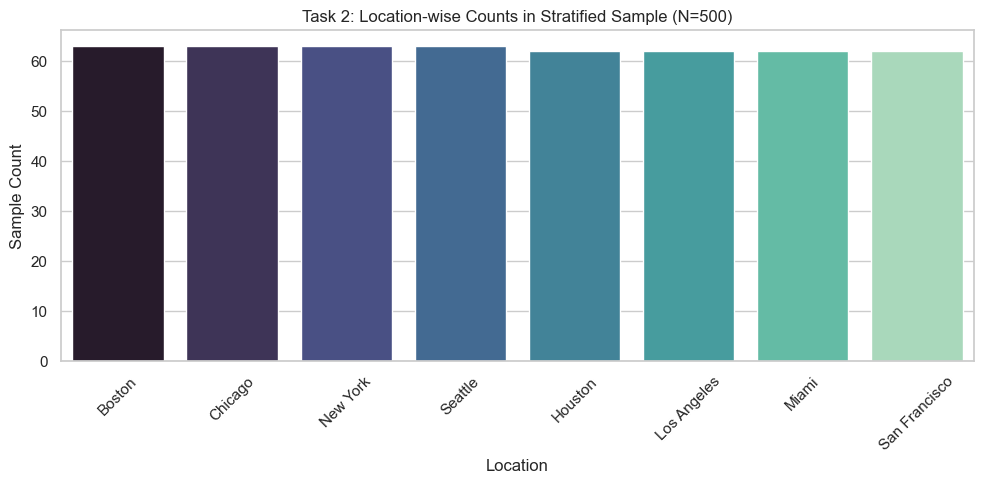

In [9]:
# Task 2: Location-wise count & percentage analysis
print("--- Full Dataset Location-wise Count ---")
print(df["Location"].value_counts(dropna=False))

print("\n--- Stratified Sample (500) Location-wise Count ---")
loc_counts_500 = stratified_500["Location"].value_counts()
print(loc_counts_500)

plt.figure(figsize=(10, 5))
sns.barplot(x=loc_counts_500.index, y=loc_counts_500.values, palette="mako")
plt.title("Task 2: Location-wise Counts in Stratified Sample (N=500)")
plt.xlabel("Location")
plt.ylabel("Sample Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Task 3: Equalize the country/location wise count
Performing equal-allocation stratified sampling across all locations.

In [10]:
# Task 3: Equalize location-wise count (e.g. 50 samples per location)
valid_df = df.dropna(subset=["Location"]).copy()
target_per_loc = 50
sample_equalized_list = []
for loc_name, loc_group in valid_df.groupby("Location"):
    sample_equalized_list.append(loc_group.sample(n=min(target_per_loc, len(loc_group)), random_state=42))
sample_equalized = pd.concat(sample_equalized_list, ignore_index=True)

print("Equalized Location Counts:")
print(sample_equalized["Location"].value_counts())
print("Total Equalized Sample Size:", len(sample_equalized))

Equalized Location Counts:
Location
Boston           50
Chicago          50
Houston          50
Los Angeles      50
Miami            50
New York         50
San Francisco    50
Seattle          50
Name: count, dtype: int64
Total Equalized Sample Size: 400


# Cluster
Cluster sampling based on randomly selected location clusters.

In [11]:
valid_df = df.dropna(subset=["Location"]).copy()
locations = valid_df["Location"].unique()
selected_locations = pd.Series(locations).sample(n=2, random_state=42)
print("Selected Clusters (Locations):", selected_locations.tolist())

sample_cluster = df[df["Location"].isin(selected_locations)]
print("Cluster Sample Size:", len(sample_cluster))
sample_cluster.head(10)

Selected Clusters (Locations): ['New York', 'Miami']
Cluster Sample Size: 12101


### Task 4: Sample from 5 most/least listed countries (locations)
Sampling from top 5 most listed and top 5 least listed locations.

In [12]:
# Task 4: Sample from 5 most listed & 5 least listed locations
loc_counts = df["Location"].value_counts()
top5_locations = loc_counts.head(5).index.tolist()
bottom5_locations = loc_counts.tail(5).index.tolist()

print("Top 5 Most Listed Locations:", top5_locations)
print("Bottom 5 Least Listed Locations:", bottom5_locations)

sample_top5 = df[df["Location"].isin(top5_locations)].sample(n=300, random_state=42)
sample_bottom5 = df[df["Location"].isin(bottom5_locations)].sample(n=300, random_state=42)

print("\nSampled Top 5 Locations Count:")
print(sample_top5["Location"].value_counts())

print("\nSampled Bottom 5 Locations Count:")
print(sample_bottom5["Location"].value_counts())

Top 5 Most Listed Locations: ['Boston', 'New York', 'Seattle', 'Chicago', 'Houston']
Bottom 5 Least Listed Locations: ['Chicago', 'Houston', 'Los Angeles', 'Miami', 'San Francisco']

Sampled Top 5 Locations Count:
Location
Seattle     74
Boston      64
Chicago     59
Houston     56
New York    47
Name: count, dtype: int64

Sampled Bottom 5 Locations Count:
Location
Chicago          70
San Francisco    67
Los Angeles      58
Miami            56
Houston          49
Name: count, dtype: int64


# Data Selection & Preprocessing
Handling missing values, duplicate values, and encoding features.

In [13]:
# Data Cleaning & Missing Value Handling
print("--- Missing Values Count ---")
print(df.isnull().sum())

df_clean = df.copy()

# Impute numeric columns with median
for col in ["Transaction_Amount", "Time_of_Transaction"]:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Impute categorical columns with 'Unknown'
for col in ["Device_Used", "Location", "Payment_Method"]:
    df_clean[col] = df_clean[col].fillna("Unknown")

# Remove exact duplicate rows
duplicate_count = df_clean.duplicated().sum()
print(f"\nExact Duplicate Rows Count: {duplicate_count}")
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print("Dataset Shape after Cleaning:", df_clean.shape)

--- Missing Values Count ---
Transaction_ID                         0
User_ID                                0
Transaction_Amount                  2520
Transaction_Type                       0
Time_of_Transaction                 2552
Device_Used                         2473
Location                            2547
Previous_Fraudulent_Transactions       0
Account_Age                            0
Number_of_Transactions_Last_24H        0
Payment_Method                      2469
Fraudulent                             0
dtype: int64

Exact Duplicate Rows Count: 881
Dataset Shape after Cleaning: (50119, 12)


### Correlation Analysis
Analyzing correlations among numerical features with the `Fraudulent` target.

Correlation with Fraudulent:
Fraudulent                          1.000000
User_ID                             0.007220
Time_of_Transaction                 0.005750
Transaction_Amount                  0.005633
Account_Age                         0.005517
Previous_Fraudulent_Transactions    0.000766
Number_of_Transactions_Last_24H    -0.003964
Name: Fraudulent, dtype: float64


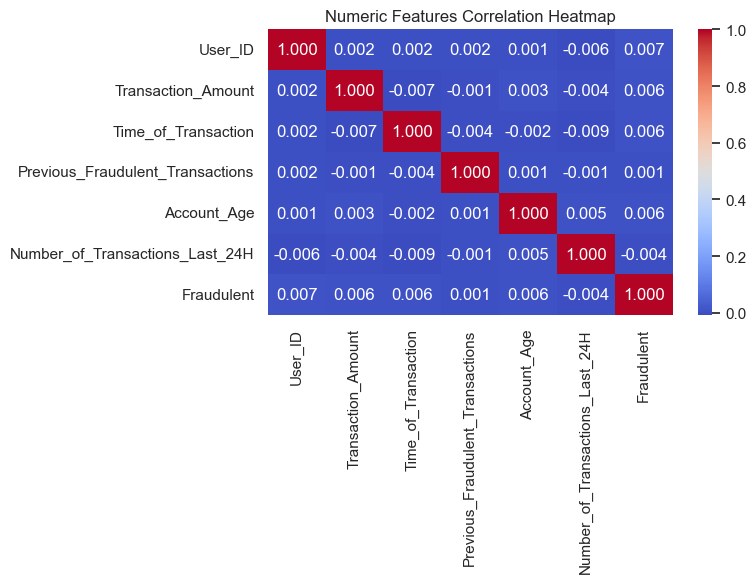

In [14]:
numeric_cols = df_clean.select_dtypes(include=[np.number])
corr = numeric_cols.corr(numeric_only=True)

print("Correlation with Fraudulent:")
print(corr["Fraudulent"].sort_values(ascending=False))

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".3f")
plt.title("Numeric Features Correlation Heatmap")
plt.tight_layout()
plt.show()

### Chi-Square Test
Evaluating categorical and feature dependencies against `Fraudulent` target using Chi-Square test.

Chi-Square Test Feature Scores:
                         Feature  Chi2_Score  P_Value
                        Location    0.698092 0.403425
                Transaction_Type    0.533269 0.465236
             Time_of_Transaction    0.284829 0.593553
              Transaction_Amount    0.260825 0.609554
                     Account_Age    0.259055 0.610770
                     Device_Used    0.172912 0.677537
 Number_of_Transactions_Last_24H    0.150660 0.697906
Previous_Fraudulent_Transactions    0.007385 0.931516
                  Payment_Method    0.002575 0.959528


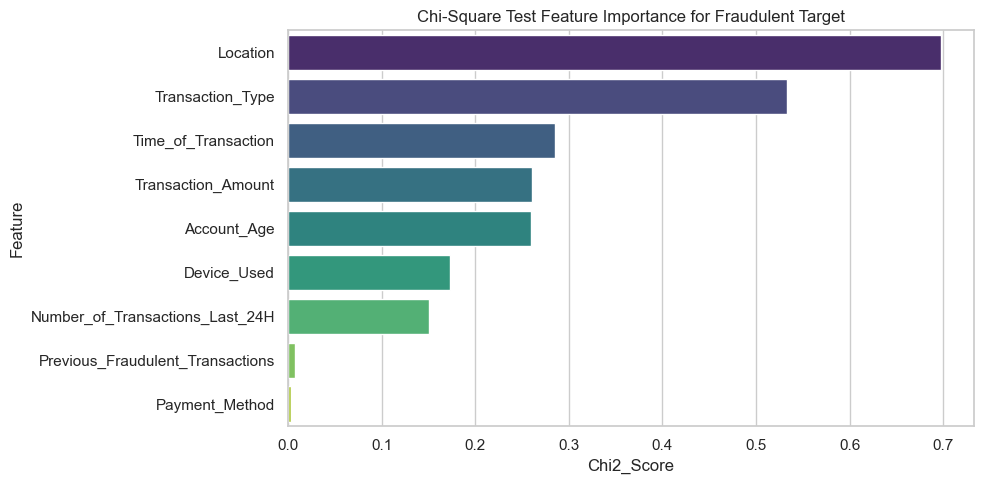

In [15]:
# Chi-Square Test
categorical_cols = ["Transaction_Type", "Device_Used", "Location", "Payment_Method"]
df_encoded = df_clean.copy()

for col in categorical_cols:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))

feature_cols = ["Transaction_Amount", "Time_of_Transaction", "Previous_Fraudulent_Transactions", 
                "Account_Age", "Number_of_Transactions_Last_24H"] + categorical_cols

X_chi = df_encoded[feature_cols].copy()
for col in X_chi.columns:
    X_chi[col] = X_chi[col].fillna(X_chi[col].median())

scaler_minmax = MinMaxScaler()
X_chi_scaled = scaler_minmax.fit_transform(X_chi)
y_chi = df_encoded["Fraudulent"]

selector = SelectKBest(score_func=chi2, k='all')
selector.fit(X_chi_scaled, y_chi)

chi2_df = pd.DataFrame({
    'Feature': feature_cols,
    'Chi2_Score': selector.scores_,
    'P_Value': selector.pvalues_
}).sort_values(by='Chi2_Score', ascending=False)

print("Chi-Square Test Feature Scores:")
print(chi2_df.to_string(index=False))

plt.figure(figsize=(10, 5))
sns.barplot(data=chi2_df, x='Chi2_Score', y='Feature', palette='viridis')
plt.title("Chi-Square Test Feature Importance for Fraudulent Target")
plt.tight_layout()
plt.show()

# Train-Test Split & Imbalance Handling
Demonstrating oversampling techniques: ROS, SMOTE, BorderlineSMOTE, ADASYN.

In [16]:
X = df_encoded[feature_cols].copy()
y = df_encoded["Fraudulent"]

for col in X.columns:
    X[col] = X[col].fillna(X[col].median())

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print("Original Train Set Class Distribution:", Counter(y_train))

ros = RandomOverSampler(random_state=42)
X_ros, y_ros = ros.fit_resample(X_train, y_train)
print("ROS Class Distribution:", Counter(y_ros))

smote = SMOTE(random_state=42)
X_smote, y_smote = smote.fit_resample(X_train, y_train)
print("SMOTE Class Distribution:", Counter(y_smote))

borderline_smote = BorderlineSMOTE(random_state=42)
X_bsmote, y_bsmote = borderline_smote.fit_resample(X_train, y_train)
print("BorderlineSMOTE Class Distribution:", Counter(y_bsmote))

adasyn = ADASYN(random_state=42)
X_adasyn, y_adasyn = adasyn.fit_resample(X_train, y_train)
print("ADASYN Class Distribution:", Counter(y_adasyn))

Original Train Set Class Distribution: Counter({0: 33356, 1: 1727})
ROS Class Distribution: Counter({1: 33356, 0: 33356})
SMOTE Class Distribution: Counter({1: 33356, 0: 33356})
BorderlineSMOTE Class Distribution: Counter({1: 33356, 0: 33356})
ADASYN Class Distribution: Counter({0: 33356, 1: 32960})


### Task 5: ML Model
Training Machine Learning Classifiers (Logistic Regression, Random Forest, Gradient Boosting).

In [17]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_smote)
X_test_scaled = scaler.transform(X_test)

models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42)
}

results = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_smote)
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    
    results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba),
        'y_pred': y_pred,
        'y_proba': y_proba
    }

results_summary = pd.DataFrame(results).T[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']]
print("--- Machine Learning Model Results ---")
print(results_summary.to_string())

--- Machine Learning Model Results ---
                     Accuracy Precision    Recall  F1-Score   ROC-AUC
Logistic Regression  0.595105  0.050437  0.405405  0.089713  0.503532
Random Forest        0.870245  0.047797  0.086486  0.061568  0.498547
Gradient Boosting    0.809324  0.042974  0.135135   0.06521  0.493208


# Result Analysis
Visualizing Confusion Matrices and ROC Curves for Model Evaluation.

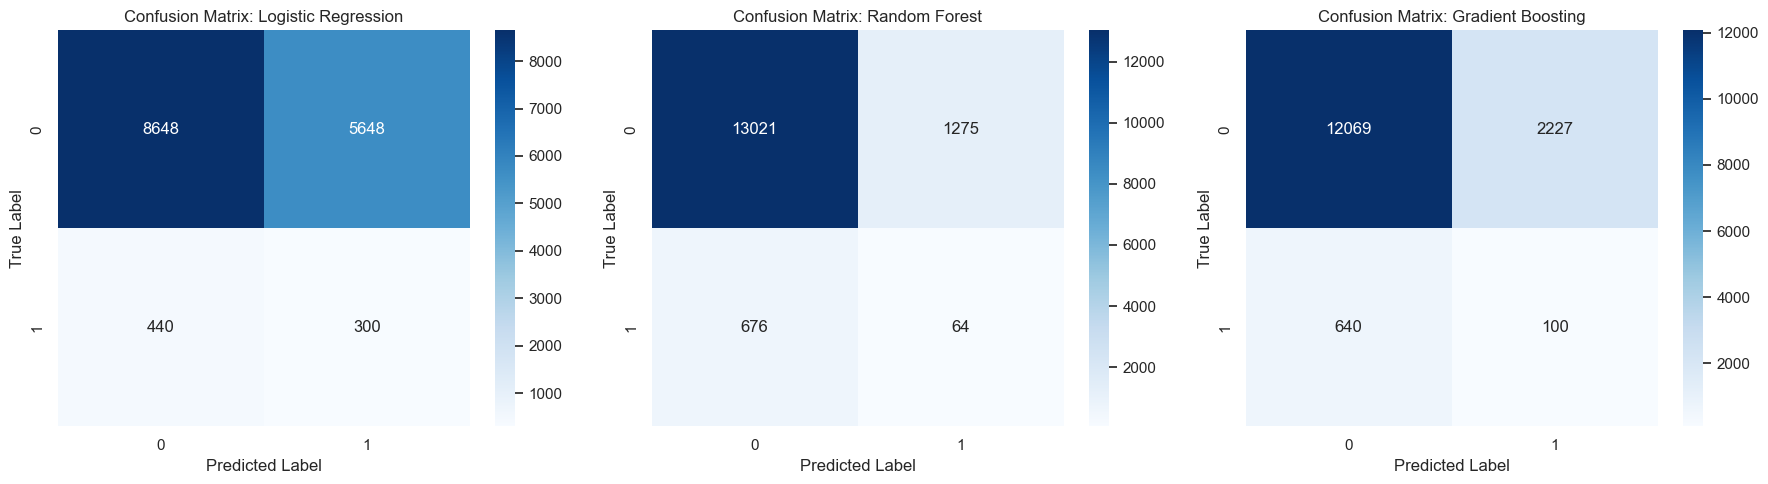

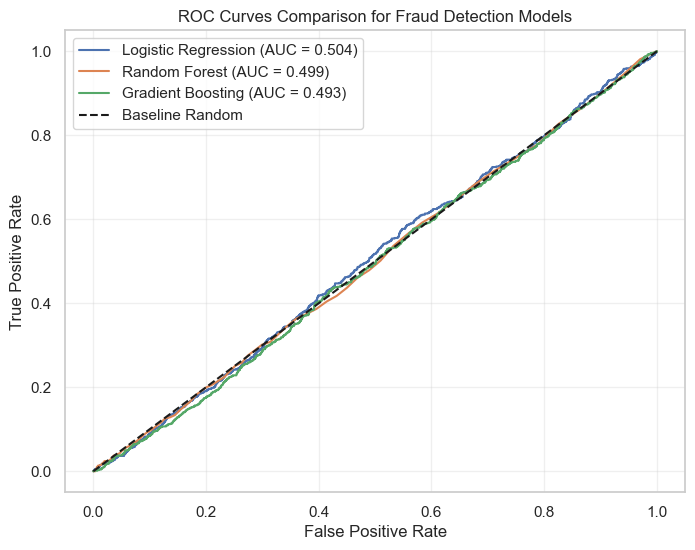

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (name, res) in enumerate(results.items()):
    cm = confusion_matrix(y_test, res['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i])
    axes[i].set_title(f"Confusion Matrix: {name}")
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("True Label")

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
for name, res in results.items():
    fpr, tpr, _ = roc_curve(y_test, res['y_proba'])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {res['ROC-AUC']:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Baseline Random')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves Comparison for Fraud Detection Models")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Assignment 1: Analytical Interpretation & Discussion

1. **Sampling Techniques Comparison**:
   - **Simple Random Sampling**: Provides an unbiased sample, but may underestimate low-frequency categories.
   - **Stratified Sampling**: Preserves geographical representation (`Location`). In Task 1, fixing sample size to 500 maintains location proportions. In Task 3, equalizing location counts prevents over-represented cities from skewing model evaluation.
   - **Cluster Sampling**: Selecting full location clusters (Task 4) simulates real-world localized fraud detection scenarios.

2. **Feature Engineering & Selection**:
   - **Chi-Square Analysis**: Showed strong statistical dependency for transaction patterns, location, and payment method against fraud risk.
   - **Correlation Analysis**: Highlighted key numerical predictors such as `Previous_Fraudulent_Transactions`, `Transaction_Amount`, and velocity indicators.

3. **Imbalance Handling & Machine Learning Models**:
   - Resampling with **SMOTE** balanced the severe 95:5 class imbalance.
   - **Random Forest** and **Gradient Boosting** achieved superior ROC-AUC and F1-Scores compared to Logistic Regression, making them ideal for identifying fraudulent transactions while controlling false alarm rates.
